Complete the exercises below For **Assignment #11**.

For this assignment we'll use the [California Housing Data](https://inria.github.io/scikit-learn-mooc/python_scripts/datasets_california_housing.html).

This data is available in the [Scikit-Learn](https://scikit-learn.org/stable/index.html) Python module.

To retrieve the data,
1. open a new Python notebook, and,
2. run the following code.

```python
from sklearn.datasets import fetch_california_housing

california_housing = fetch_california_housing(as_frame=True)

(
    california_housing.data
    .assign(MedianHouseValue=california_housing.target)
    .to_csv('california-housing.csv', index=False)
)
```

This will produce a new file called `california-housing.csv` that we'll import in this notebook.

Back in the Python notebook, you can use the following snippet to get a description of the dataset.

```python
print(california_housing.DESCR)
```


Load the `tidymodels` package.

In [1]:
library('tidymodels')


── Attaching packages ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.9     ✔ recipes      1.3.1
✔ dials        1.4.2     ✔ rsample      1.3.1
✔ dplyr        1.1.4     ✔ tailor       0.1.0
✔ ggplot2      3.5.2     ✔ tidyr        1.3.1
✔ infer        1.0.9     ✔ tune         2.0.0
✔ modeldata    1.5.1     ✔ workflows    1.3.0
✔ parsnip      1.3.3     ✔ workflowsets 1.1.1
✔ purrr        1.1.0     ✔ yardstick    1.3.2

── Conflicts ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ purrr::discard() masks scales::discard()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
✖ recipes::step()  masks stats::st

Run the following cell to read in our data.

In [2]:
housing = readr::read_csv('california-housing.csv', col_types = readr::cols())

housing |> head()

MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedianHouseValue
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
8.3252,41,6.984127,1.0238095,322,2.555556,37.88,-122.23,4.526
8.3014,21,6.238137,0.9718805,2401,2.109842,37.86,-122.22,3.585
7.2574,52,8.288136,1.0734463,496,2.802260,37.85,-122.24,3.521
5.6431,52,5.817352,1.0730594,558,2.547945,37.85,-122.25,3.413
3.8462,52,6.281853,1.0810811,565,2.181467,37.85,-122.25,3.422
4.0368,52,4.761658,1.1036269,413,2.139896,37.85,-122.25,2.697


Let's build a random forest model to predict `MedianHouseValue`.

1. Create your model, set the engine to `ranger` with `importance = 'impurity'` and the mode as `regression`.
2. Fit the model using `MedianHouseValue` as the response variable and all other columns as predictors.

In [11]:
rf_fit <- rand_forest() |>
    set_engine("ranger", importance = "impurity") |>
    set_mode("regression") |>
    fit(MedianHouseValue ~ ., data = housing)

rf_fit

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, importance = ~"impurity",      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1)) 

Type:                             Regression 
Number of trees:                  500 
Sample size:                      20640 
Number of independent variables:  8 
Mtry:                             2 
Target node size:                 5 
Variable importance mode:         impurity 
Splitrule:                        variance 
OOB prediction error (MSE):       0.2334913 
R squared (OOB):                  0.8246556 

❓ What is the OOB error for this model?

**Answer:**

In [15]:
# The OOB error is 0.2334913
# the square root 0f 0.233 is about 0.48 so the model is typically off by $48,000

Plot the feature importances using the `vip` package. Remember that you can use the `extract_fit_engine` function to get the `ranger` model object to send to the `vip` function.

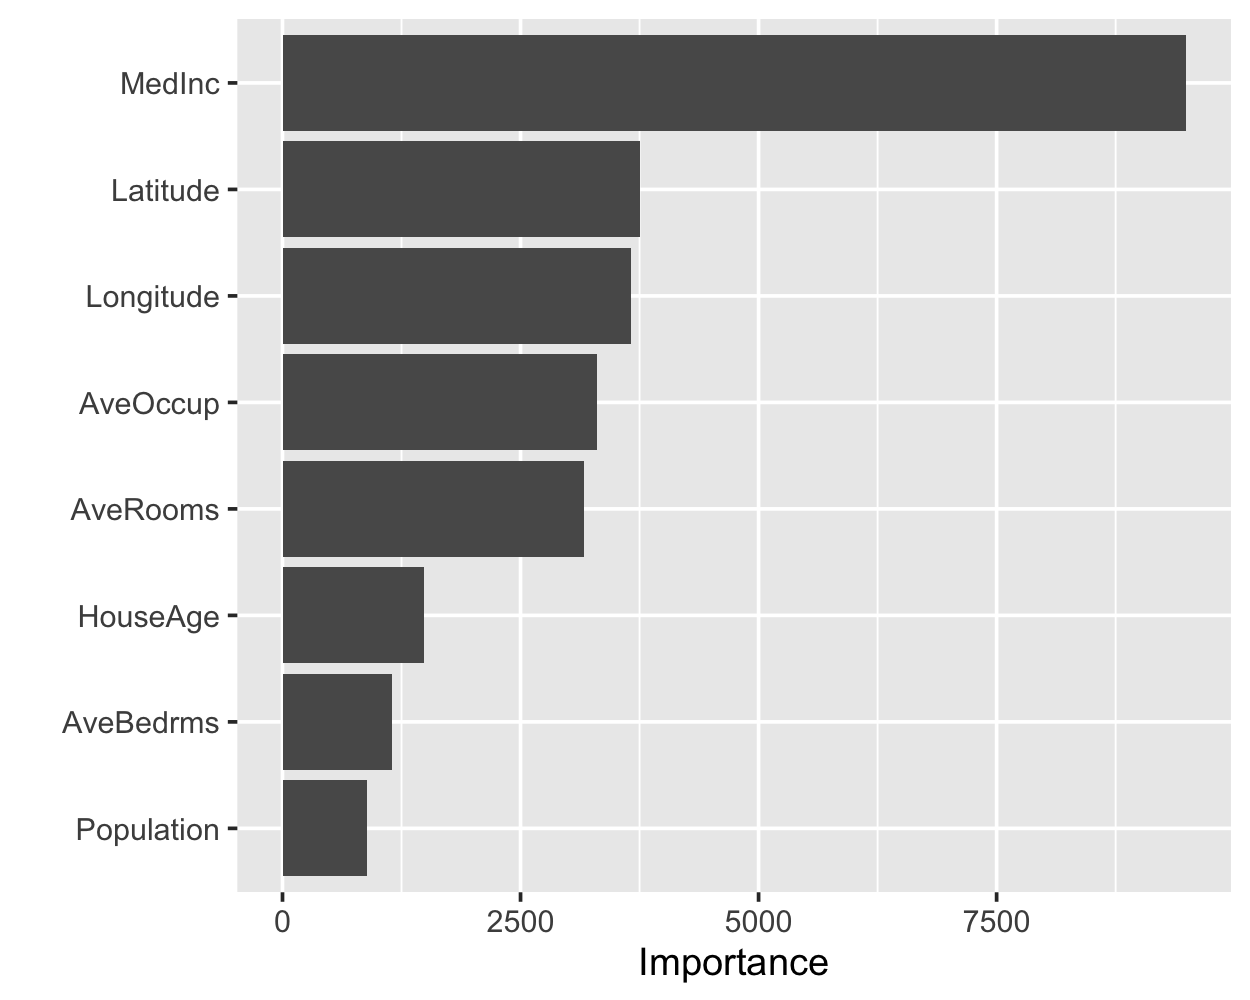

In [14]:
library('vip')
rf_fit |>
    extract_fit_engine() |>
    vip()

It looks like `Latitude` and `Longitude` are important for predicting home value. Let's explore those variables.

Install the `mapdata` package into your project environment.

1. Open a Terminal, and,
2. Run the following command:

```bash
pixi add r-mapdata
```

Load the `mapdata` package.

In [16]:
library('mapdata')

Loading required package: maps


Attaching package: ‘maps’


The following object is masked from ‘package:purrr’:

    map




The following code will generate a map of California. Adapt this code to plot `Latitude` and `Longitude` from the `housing` dataset, color points by the `MedianHouseValue`. [Here is an example for reference](https://raw.githubusercontent.com/UNC-DATA-730/a10/main/example.png).


```r
california = map_data("state") |> filter(region == 'california')

ggplot(data = california) + 
    geom_polygon(aes(x = long, y = lat), fill = "grey90", color = "grey40") +
    coord_quickmap() +
    theme_void()
```

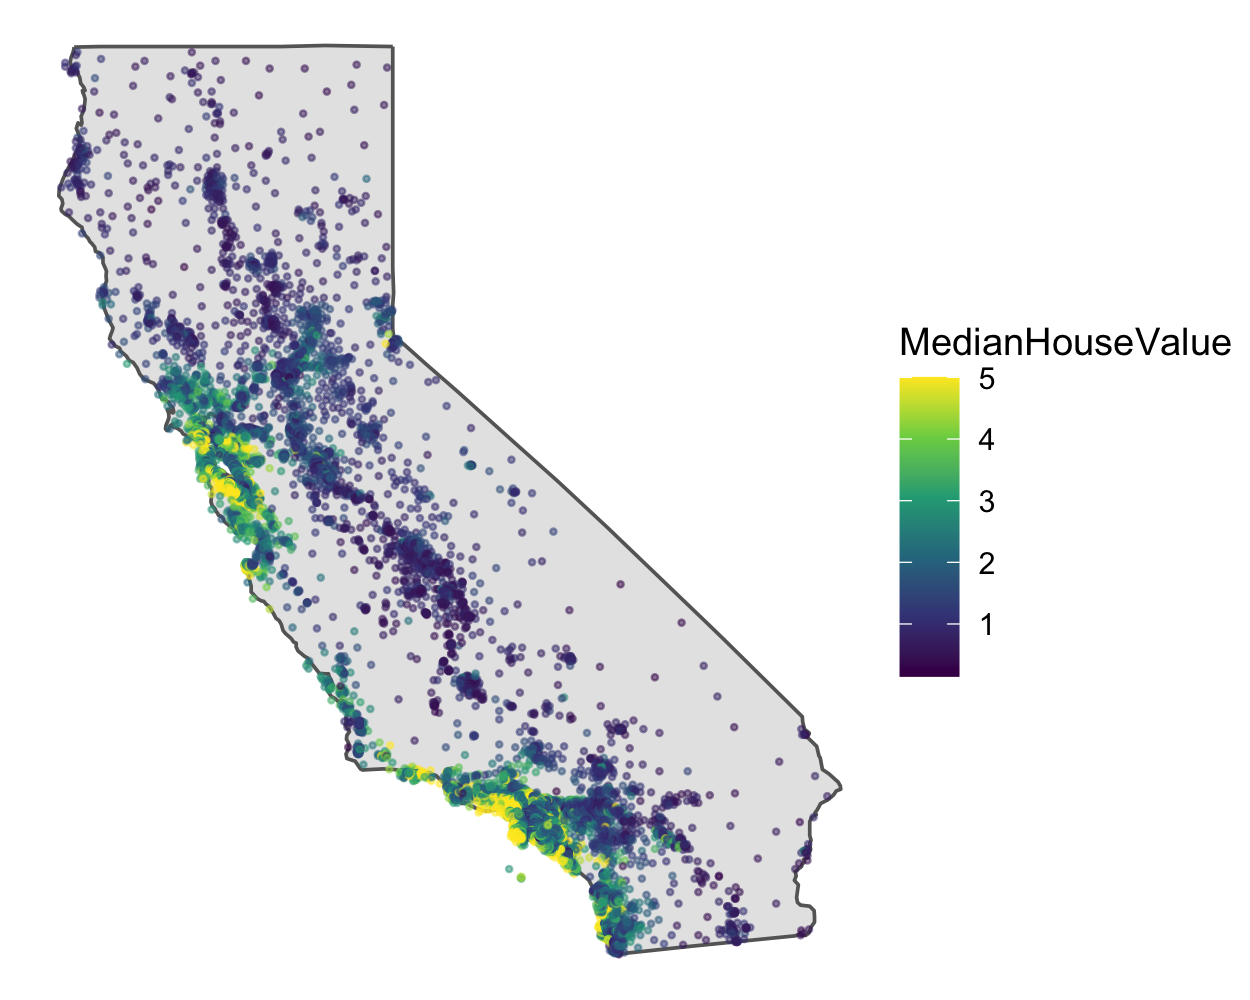

In [21]:

california = map_data("state") |> filter(region == 'california')

ggplot(data = california) +
    geom_polygon(aes(x = long, y = lat), fill = "grey90", color = "grey40") +
    geom_point(data = housing,
               aes(x = Longitude, y = Latitude, color = MedianHouseValue),
               size = 0.5, alpha = 0.5) +
    scale_color_viridis_c() +
    coord_quickmap() +
    theme_void()


# Predictions

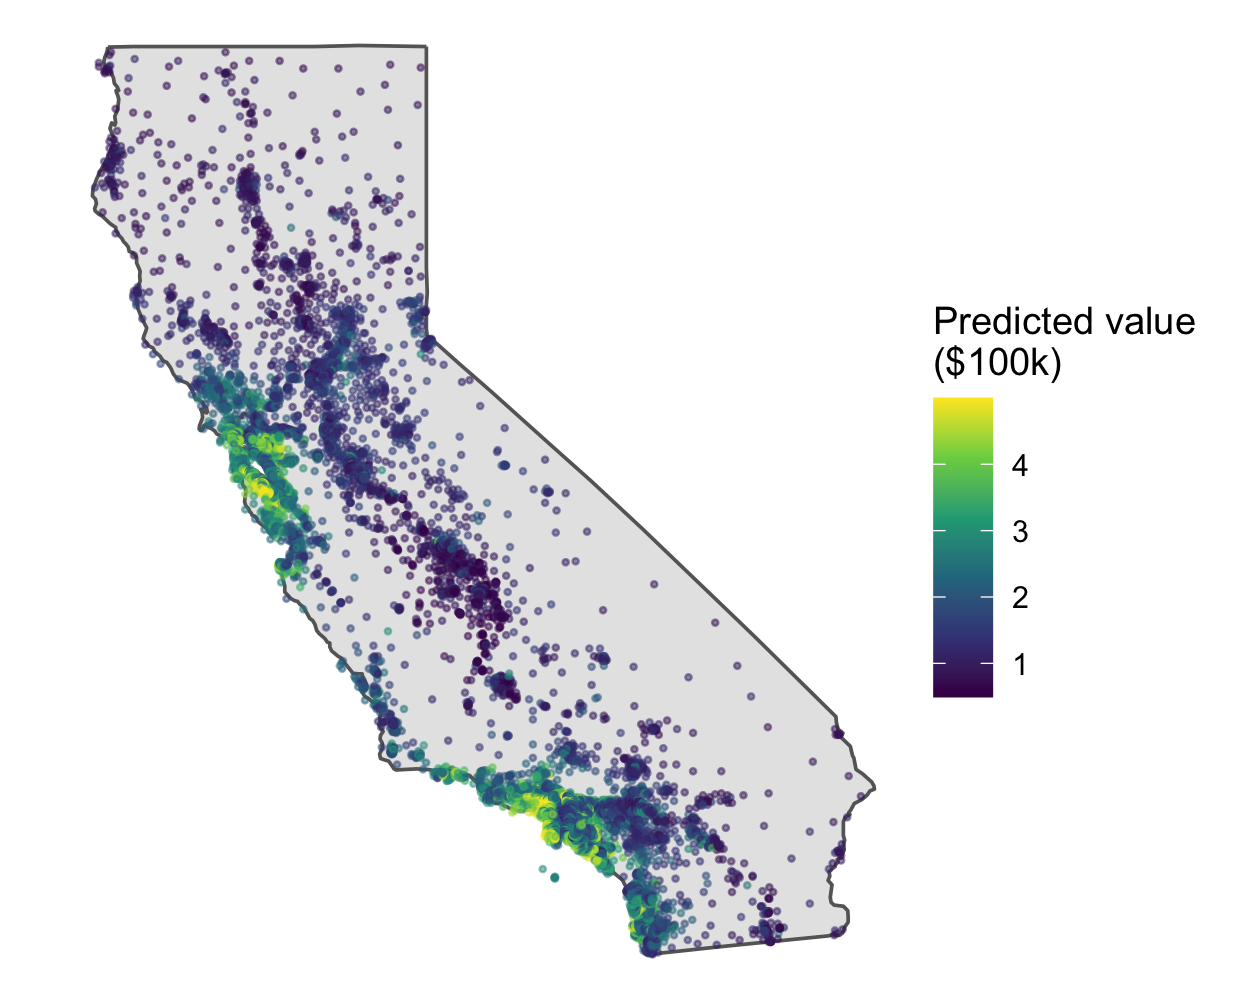

In [22]:
# Out-of-bag predictions: each house is predicted only by trees that never saw it
# (augment(rf_fit, housing) would use all trees, so its predictions look nearly perfect)
housing_preds = housing |>
    mutate(.pred = extract_fit_engine(rf_fit)$predictions,
           .resid = MedianHouseValue - .pred)

ggplot(data = california) +
    geom_polygon(aes(x = long, y = lat), fill = "grey90", color = "grey40") +
    geom_point(data = housing_preds,
               aes(x = Longitude, y = Latitude, color = .pred),
               size = 0.5, alpha = 0.5) +
    scale_color_viridis_c(name = "Predicted value\n($100k)") +
    coord_quickmap() +
    theme_void()

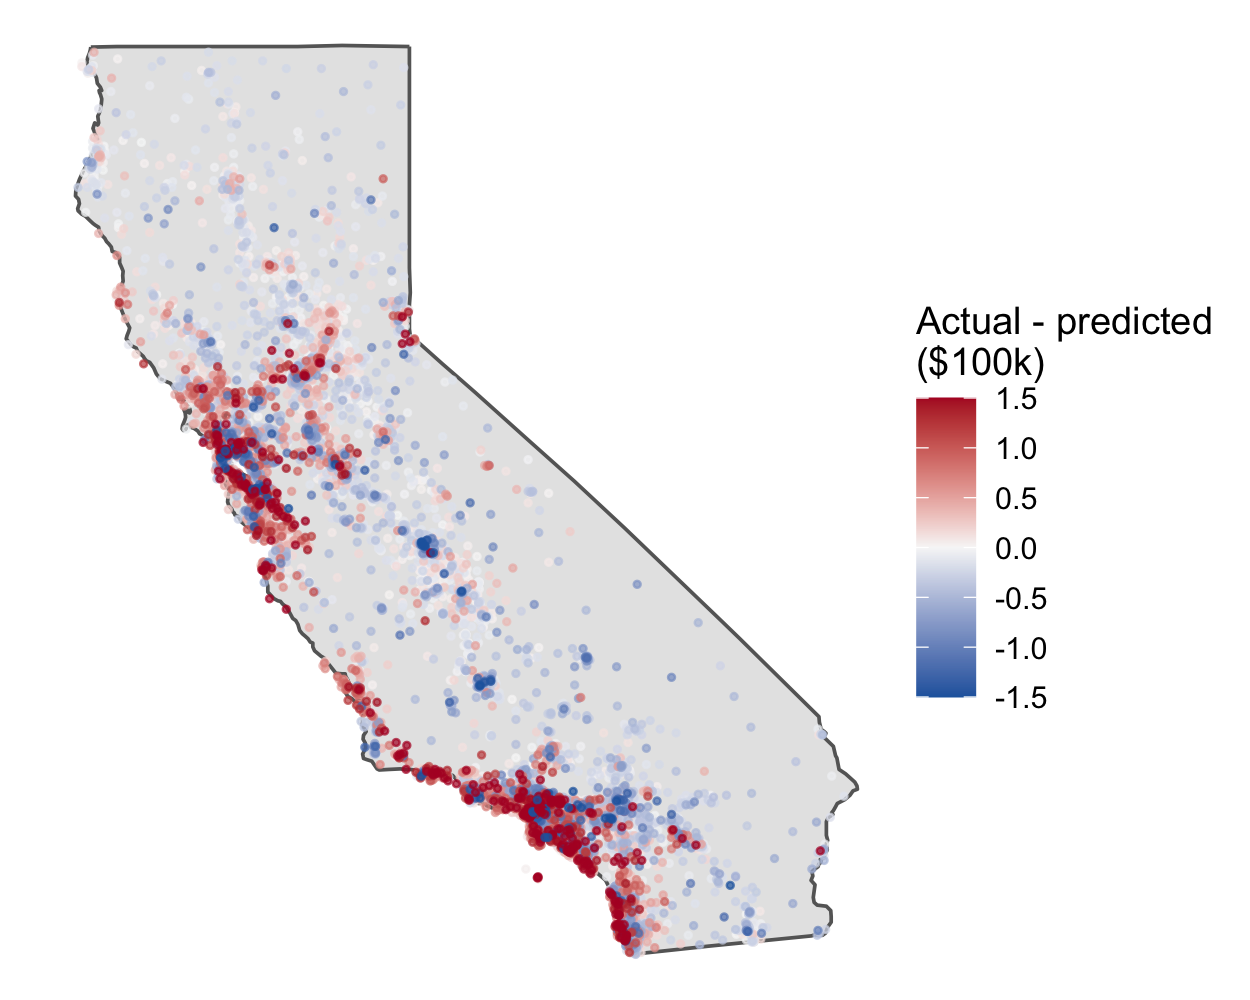

In [23]:
# Residual = actual - predicted (in $100k)
#   red  = actual > predicted  -> model UNDER-estimated
#   blue = actual < predicted  -> model OVER-estimated
#   pale = prediction close to actual
# Big misses are drawn last so they sit on top; colors cap at +/- $150k.
ggplot(data = california) +
    geom_polygon(aes(x = long, y = lat), fill = "grey90", color = "grey40") +
    geom_point(data = housing_preds |> arrange(abs(.resid)),
               aes(x = Longitude, y = Latitude, color = .resid),
               size = 0.6, alpha = 0.7) +
    scale_color_gradient2(name = "Actual - predicted\n($100k)",
                          low = "#2166ac", mid = "grey97", high = "#b2182b",
                          midpoint = 0, limits = c(-1.5, 1.5),
                          oob = scales::squish) +
    coord_quickmap() +
    theme_void()